# Homework 6.2 - Step 9

## LLM Attention Critic with Context Interventions

Large attention weights are not automatically evidence of causal importance.

This notebook therefore uses the following order:

$$
\text{freeze attention evidence}
\rightarrow
\text{ask the LLM for testable predictions}
\rightarrow
\text{record the LLM response}
\rightarrow
\text{run context interventions}
\rightarrow
\text{student critique}.
$$

The LLM must make its interpretation **before** seeing the intervention results.

## Intervention questions

For the selected 20%-anchor ambiguous attention model, the notebook tests:

### High-attention replacement

Replace the highest-attended **non-center** context position.

### Low-attention control

Replace the lowest-attended non-center context position.

### Context permutation

Randomly permute all non-center context symbols while leaving the center observed glyph unchanged.

For a true source token $$t_i$$, define

$$
\Delta P_{\mathrm{true}}
=
P_\theta(t_i\mid C_i)
-
P_\theta(t_i\mid C_i^{\mathrm{intervention}}).
$$

If attention weights correspond to useful context, a natural testable prediction is that high-attention replacement should, on average, perturb the output more than the low-attention control.

That is an empirical question, not an assumption.

In [1]:
from pathlib import Path
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw6_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw6_2"
MODEL_DIR = DATA_DIR / "ambiguous_models"

manifest = json.loads(
    (
        DATA_DIR
        / "task2_frozen_information_manifest.json"
    ).read_text(
        encoding="utf-8"
    )
)

selection = json.loads(
    (
        DATA_DIR
        / "task6_selected_attention_architecture.json"
    ).read_text(
        encoding="utf-8"
    )
)

SELECTED_CONFIG = selection[
    "selected_config"
]

K = int(
    manifest["source_vocabulary_size"]
)

ANALYSIS_LEVEL = "20"
SEED = 63869
INTERVENTION_SAMPLE_SIZE = 1000
DROPOUT = 0.10

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

rng = np.random.default_rng(
    SEED
)

print("Device:", DEVICE)
print("Analysis anchor level:", ANALYSIS_LEVEL)

Device: cuda
Analysis anchor level: 20


# Reconstruct the frozen ambiguous observed-symbol vocabulary

In [2]:
def absolute_from_manifest(relative_path):
    normalized = str(relative_path).replace("\\", "/")
    return PROJECT_ROOT / Path(normalized)


def pick_column(frame, candidates, label):
    lowered = {
        column.lower(): column
        for column in frame.columns
    }

    for candidate in candidates:
        if candidate.lower() in lowered:
            return lowered[candidate.lower()]

    for column in frame.columns:
        low = column.lower()

        if any(
            candidate.lower() in low
            for candidate in candidates
        ):
            return column

    raise KeyError(
        f"Could not identify {label}. "
        f"Available columns: {list(frame.columns)}"
    )


GLYPH_CANDIDATES = [
    "glyph_id",
    "glyph",
    "glyph_index",
    "token",
]

SOURCE_CANDIDATES = [
    "source_token_id",
    "syllable_id",
    "source_id",
    "token_id",
]


def load_raw_split(split_name):
    frame = pd.read_csv(
        absolute_from_manifest(
            manifest["splits"][
                split_name
            ]
        )
    )

    glyph_col = pick_column(
        frame,
        GLYPH_CANDIDATES,
        "glyph ID",
    )

    return frame[
        glyph_col
    ].to_numpy()


pseudo_20 = pd.read_csv(
    absolute_from_manifest(
        manifest[
            "pseudo_label_maps"
        ][ANALYSIS_LEVEL]
    )
)

raw_glyph_ids = np.array(
    sorted(
        pseudo_20[
            "glyph_id"
        ].unique()
    )
)

raw_source_ids = np.array(
    sorted(
        pseudo_20[
            "source_token_id"
        ].unique()
    )
)

source_to_index = {
    raw_id: index
    for index, raw_id
    in enumerate(raw_source_ids)
}

index_to_source = {
    index: raw_id
    for raw_id, index
    in source_to_index.items()
}

merge_pairs = pd.read_csv(
    DATA_DIR
    / "task7_merge_pairs.csv"
)

original_to_group = {}
group_members = {}

for row in merge_pairs.itertuples():
    key = (
        "merged",
        int(row.merge_group_id),
    )

    members = [
        row.glyph_a,
        row.glyph_b,
    ]

    group_members[key] = members

    for glyph in members:
        original_to_group[
            glyph
        ] = key


for glyph in raw_glyph_ids:
    if glyph not in original_to_group:
        key = (
            "single",
            glyph,
        )

        group_members[key] = [
            glyph
        ]

        original_to_group[
            glyph
        ] = key


ordered_groups = sorted(
    group_members.keys(),
    key=lambda key: (
        0 if key[0] == "single" else 1,
        str(key[1]),
    ),
)

group_to_observed_index = {
    key: index
    for index, key
    in enumerate(ordered_groups)
}

original_to_observed_index = {
    glyph: group_to_observed_index[
        original_to_group[glyph]
    ]
    for glyph in raw_glyph_ids
}


def apply_merge(raw_sequence):
    return np.array(
        [
            original_to_observed_index[
                glyph
            ]
            for glyph
            in raw_sequence
        ],
        dtype=np.int64,
    )


train_raw = load_raw_split(
    "train"
)

test_raw = load_raw_split(
    "test"
)

train_observed = apply_merge(
    train_raw
)

test_observed = apply_merge(
    test_raw
)

AMBIGUOUS_VOCAB_SIZE = len(
    ordered_groups
)

print(
    "Ambiguous observed vocabulary:",
    AMBIGUOUS_VOCAB_SIZE,
)

Ambiguous observed vocabulary: 3012


# Load the evaluation-only true labels

Step 9 occurs after model fitting and final decoding evaluation, so the hidden map may now be used to score the intervention outcomes.

It is not included in the LLM's pre-intervention prompt.

In [3]:
hidden_map = pd.read_csv(
    absolute_from_manifest(
        manifest[
            "evaluation_only_hidden_map"
        ]
    )
)

hidden_glyph_col = pick_column(
    hidden_map,
    GLYPH_CANDIDATES,
    "hidden-map glyph ID",
)

hidden_source_col = pick_column(
    hidden_map,
    SOURCE_CANDIDATES,
    "hidden-map source-token ID",
)

true_inverse_map = dict(
    zip(
        hidden_map[
            hidden_glyph_col
        ],
        hidden_map[
            hidden_source_col
        ],
    )
)

test_true_source = np.array(
    [
        true_inverse_map[glyph]
        for glyph in test_raw
    ]
)

test_true_index = np.array(
    [
        source_to_index[
            source
        ]
        for source
        in test_true_source
    ],
    dtype=np.int64,
)

# Reconstruct the selected attention model

In [4]:
class AttentionBlock(nn.Module):
    def __init__(
        self,
        embed_dim,
        num_heads,
        dropout,
    ):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(
                embed_dim,
                2 * embed_dim,
            ),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(
                2 * embed_dim,
                embed_dim,
            ),
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(
        self,
        x,
        return_weights=False,
    ):
        attended, weights = (
            self.attention(
                x,
                x,
                x,
                need_weights=True,
                average_attn_weights=False,
            )
        )

        x = self.norm1(
            x
            + self.dropout(
                attended
            )
        )

        x = self.norm2(
            x
            + self.dropout(
                self.feed_forward(x)
            )
        )

        if return_weights:
            return x, weights

        return x


class CenteredAttentionDecoder(nn.Module):
    def __init__(
        self,
        observed_vocab_size,
        source_vocab_size,
        radius,
        embed_dim,
        num_heads,
        num_layers,
        dropout,
    ):
        super().__init__()

        self.radius = int(radius)

        self.glyph_embedding = nn.Embedding(
            observed_vocab_size,
            embed_dim,
        )

        self.position_embedding = nn.Embedding(
            2 * self.radius + 1,
            embed_dim,
        )

        self.blocks = nn.ModuleList([
            AttentionBlock(
                embed_dim,
                num_heads,
                dropout,
            )
            for _ in range(
                num_layers
            )
        ])

        self.output = nn.Linear(
            embed_dim,
            source_vocab_size,
        )

    def forward(
        self,
        windows,
        return_attention=False,
    ):
        positions = torch.arange(
            windows.shape[1],
            device=windows.device,
        )

        x = (
            self.glyph_embedding(
                windows
            )
            + self.position_embedding(
                positions
            )[None, :, :]
        )

        weights_by_layer = []

        for block in self.blocks:
            if return_attention:
                x, weights = block(
                    x,
                    return_weights=True,
                )

                weights_by_layer.append(
                    weights
                )

            else:
                x = block(x)

        logits = self.output(
            x[:, self.radius, :]
        )

        if return_attention:
            return logits, weights_by_layer

        return logits


checkpoint = torch.load(
    MODEL_DIR
    / (
        "attention_ambiguous_"
        "anchors_20.pt"
    ),
    map_location=DEVICE,
)

model = CenteredAttentionDecoder(
    observed_vocab_size=(
        checkpoint[
            "observed_vocab_size"
        ]
    ),
    source_vocab_size=K,
    radius=int(
        checkpoint[
            "selected_config"
        ]["radius"]
    ),
    embed_dim=int(
        checkpoint[
            "selected_config"
        ]["embed_dim"]
    ),
    num_heads=int(
        checkpoint[
            "selected_config"
        ]["num_heads"]
    ),
    num_layers=int(
        checkpoint[
            "selected_config"
        ]["num_layers"]
    ),
    dropout=DROPOUT,
).to(DEVICE)

model.load_state_dict(
    checkpoint["state_dict"]
)

model.eval()

RADIUS = int(
    checkpoint[
        "selected_config"
    ]["radius"]
)

WINDOW_LENGTH = (
    2 * RADIUS + 1
)

print("Context radius:", RADIUS)
print("Window length:", WINDOW_LENGTH)

Context radius: 4
Window length: 9


# Freeze the evidence shown to the LLM

The pre-intervention evidence includes:

- the bijective and ambiguous decoding metrics;
- selected attention examples;
- aggregate attention-distance and entropy summaries;
- the saved attention plots.

The intervention outcomes are intentionally excluded.

In [5]:
bijective = pd.read_csv(
    DATA_DIR
    / "task5_bijective_decoder_comparison.csv"
)

ambiguous = pd.read_csv(
    DATA_DIR
    / "task7_ambiguous_decoder_comparison.csv"
)

advantage = pd.read_csv(
    DATA_DIR
    / "task7_attention_advantage_bijective_vs_ambiguous.csv"
)

selected_examples = pd.read_csv(
    DATA_DIR
    / "task8_selected_attention_examples.csv"
)

attention_summary_text = (
    DATA_DIR
    / "task8_attention_aggregate_summary.csv"
).read_text(
    encoding="utf-8"
)

evidence_parts = [
    "BIJECTIVE DECODER RESULTS:",
    bijective.to_string(index=False),
    "",
    "AMBIGUOUS DECODER RESULTS:",
    ambiguous.to_string(index=False),
    "",
    "ATTENTION ADVANTAGE COMPARISON:",
    advantage.to_string(index=False),
    "",
    "SELECTED ATTENTION EXAMPLES:",
    selected_examples.to_string(index=False),
    "",
    "AGGREGATE ATTENTION SUMMARY:",
    attention_summary_text,
    "",
    "ATTENTION FIGURES TO INSPECT:",
    "task8_attention_matrix_example_1.png",
    "task8_attention_profile_example_1.png",
    "task8_attention_matrix_example_2.png",
    "task8_attention_profile_example_2.png",
]

fixed_evidence = "\n".join(
    evidence_parts
)

evidence_path = (
    DATA_DIR
    / "task9_preintervention_evidence.txt"
)

evidence_path.write_text(
    fixed_evidence,
    encoding="utf-8",
)

print(fixed_evidence)

BIJECTIVE DECODER RESULTS:
 anchor_level        model  evaluated_positions  overall_accuracy  anchored_occurrences  anchored_accuracy  unanchored_occurrences  unanchored_accuracy  all_K_map_recovery  observed_type_map_recovery  observed_test_glyph_types  unanchored_map_recovery
            5    attention                11557          0.089297                   645           0.987597                   10912             0.036199            0.024246                    0.054212                       1365                 0.002070
            5 mlp_baseline                11557          0.089210                   645           0.986047                   10912             0.036199            0.023919                    0.053480                       1365                 0.002070
           10    attention                11557          0.163797                  1100           0.982727                   10457             0.077651            0.045216                    0.101099                  

# LLM critic question

Show the LLM the four saved Task 8 attention figures together with the prompt printed below.

The LLM must make explicit predictions about the interventions before the intervention results are computed.

In [6]:
critic_question = "\n".join([
    "You are the critic for a Math 638 contextual-decipherment experiment.",
    "",
    "The model is a centered self-attention decoder for an artificial glyph cipher. Some original glyphs have been deliberately merged into ambiguous observed symbols.",
    "",
    "You are given fixed decoding results, attention summaries, and selected attention plots. You have NOT been given the context-intervention results.",
    "",
    "Answer the following questions using only the supplied evidence.",
    "",
    "1. What do the selected attention plots appear to emphasize when the same ambiguous observed glyph is decoded differently in different contexts?",
    "2. Does the aggregate evidence suggest that ambiguous occurrences use context differently from unambiguous occurrences?",
    "3. Does attention appear more helpful than the matched non-attention baseline in the ambiguous experiment than in the bijective experiment?",
    "4. Which parts of the attention interpretation are strongly supported, and which are only plausible descriptions?",
    "5. Make a specific prediction: if the highest-attended non-center context symbol is replaced, should the model's probability of the true center label change more than if the lowest-attended non-center symbol is replaced?",
    "6. Make a specific prediction about permuting all non-center context symbols while leaving the center glyph fixed.",
    "7. Would your predicted intervention effect be stronger for ambiguous occurrences than unambiguous occurrences? State your expectation and why.",
    "",
    "Important constraints:",
    "- Large attention weight is not proof of causal importance.",
    "- Do not claim the model discovered linguistic rules unless the evidence tests that claim.",
    "- Do not infer unavailable punctuation, word-boundary, or repeated-phrase features unless they were actually supplied as model inputs.",
    "- Distinguish resolving context-dependent ambiguity from naming genuinely unrevealed syllables.",
    "",
    "Return:",
    "A. Evidence-supported interpretation.",
    "B. Explicit intervention predictions.",
    "C. Claims that would exceed the current evidence.",
])

prompt = (
    critic_question
    + "\n\nFIXED PRE-INTERVENTION EVIDENCE:\n\n"
    + fixed_evidence
)

prompt_path = (
    DATA_DIR
    / "task9_llm_critic_prompt.txt"
)

prompt_path.write_text(
    prompt,
    encoding="utf-8",
)

print(prompt)
print()
print("Saved:", prompt_path.resolve())

You are the critic for a Math 638 contextual-decipherment experiment.

The model is a centered self-attention decoder for an artificial glyph cipher. Some original glyphs have been deliberately merged into ambiguous observed symbols.

You are given fixed decoding results, attention summaries, and selected attention plots. You have NOT been given the context-intervention results.

Answer the following questions using only the supplied evidence.

1. What do the selected attention plots appear to emphasize when the same ambiguous observed glyph is decoded differently in different contexts?
2. Does the aggregate evidence suggest that ambiguous occurrences use context differently from unambiguous occurrences?
3. Does attention appear more helpful than the matched non-attention baseline in the ambiguous experiment than in the bijective experiment?
4. Which parts of the attention interpretation are strongly supported, and which are only plausible descriptions?
5. Make a specific prediction: i

# LLM Response

A. Evidence-supported interpretation

1. The two selected examples show that the same merged observed symbol can be decoded as two different source tokens when its surrounding context changes. In example 1, the center-query attention is concentrated mainly at relative positions -1 and +1. In example 2, it is concentrated mainly at -3 and +1. This is evidence that the decoder conditions its decision on different surrounding positions in different contexts. It is not, by itself, evidence that those positions have a particular linguistic meaning.

2. The aggregate attention statistics suggest that ambiguous occurrences use context differently from unambiguous occurrences. Ambiguous occurrences have larger expected absolute attention distance: about 1.12-1.16 tokens for incorrect/correct ambiguous cases, compared with about 0.78-0.95 for unambiguous cases. Correct ambiguous cases also have somewhat lower attention entropy than incorrect ambiguous cases (about 0.97 versus 1.08), suggesting that successful ambiguous decisions are sometimes associated with more concentrated attention. These are descriptive associations, not causal conclusions.

3. Attention is not uniformly more helpful than the matched MLP baseline in the ambiguous experiment. In the bijective experiment the attention advantage is essentially zero on unanchored occurrences and only very small on whole-text accuracy. In the ambiguous experiment attention has a modest positive advantage at 5% and 10% anchors, but the advantage becomes negative for several metrics at 20% and 40% anchors. Therefore the evidence supports, at most, the narrower claim that attention can help in some low-anchor ambiguous conditions; it does not support a general claim that attention is superior whenever glyphs are ambiguous.

4. Strongly supported claims are: (i) the learned attention distribution changes with context, (ii) ambiguous occurrences tend to place attention farther from the center than unambiguous occurrences, and (iii) the same ambiguous observed symbol can receive different correct predictions in different contexts. Only plausible, not yet causally established, is the claim that the largest attention weights identify the context tokens that are responsible for the prediction.

B. Explicit intervention predictions

1. Replacing the highest-attended non-center symbol should, on average, change the model output more than replacing the lowest-attended non-center symbol. I would test this using both the absolute change in the true-label probability and the fraction of examples whose argmax prediction changes.

2. Permuting all non-center context symbols while leaving the center symbol fixed should usually be more disruptive than the low-attention replacement because it destroys the learned positional arrangement of the surrounding context. Its effect may be comparable to, or larger than, replacing a single top-attended position.

3. I expect both interventions to have a substantially stronger effect for ambiguous occurrences than for unambiguous occurrences. For an unambiguous center symbol, the center identity itself can often determine the pseudo-label. For a merged ambiguous center, surrounding context is required to distinguish which underlying source value is appropriate.

C. Claims that would exceed the current evidence

The current evidence does not justify saying that the model has discovered grammatical rules, word boundaries, punctuation structure, repeated phrases, or any other linguistic feature that was not explicitly supplied and tested. It also does not justify treating an attention weight as a causal attribution before intervention. Finally, contextual disambiguation of a merged symbol is different from recovering the English name of an unrevealed syllable: attention can use context to choose among values represented in the supervision without solving the identifiability problem for genuinely unrevealed names.

In [7]:
LLM_RESPONSE = r'A. Evidence-supported interpretation\n\n1. The two selected examples show that the same merged observed symbol can be decoded as two different source tokens when its surrounding context changes. In example 1, the center-query attention is concentrated mainly at relative positions -1 and +1. In example 2, it is concentrated mainly at -3 and +1. This is evidence that the decoder conditions its decision on different surrounding positions in different contexts. It is not, by itself, evidence that those positions have a particular linguistic meaning.\n\n2. The aggregate attention statistics suggest that ambiguous occurrences use context differently from unambiguous occurrences. Ambiguous occurrences have larger expected absolute attention distance: about 1.12-1.16 tokens for incorrect/correct ambiguous cases, compared with about 0.78-0.95 for unambiguous cases. Correct ambiguous cases also have somewhat lower attention entropy than incorrect ambiguous cases (about 0.97 versus 1.08), suggesting that successful ambiguous decisions are sometimes associated with more concentrated attention. These are descriptive associations, not causal conclusions.\n\n3. Attention is not uniformly more helpful than the matched MLP baseline in the ambiguous experiment. In the bijective experiment the attention advantage is essentially zero on unanchored occurrences and only very small on whole-text accuracy. In the ambiguous experiment attention has a modest positive advantage at 5% and 10% anchors, but the advantage becomes negative for several metrics at 20% and 40% anchors. Therefore the evidence supports, at most, the narrower claim that attention can help in some low-anchor ambiguous conditions; it does not support a general claim that attention is superior whenever glyphs are ambiguous.\n\n4. Strongly supported claims are: (i) the learned attention distribution changes with context, (ii) ambiguous occurrences tend to place attention farther from the center than unambiguous occurrences, and (iii) the same ambiguous observed symbol can receive different correct predictions in different contexts. Only plausible, not yet causally established, is the claim that the largest attention weights identify the context tokens that are responsible for the prediction.\n\nB. Explicit intervention predictions\n\n1. Replacing the highest-attended non-center symbol should, on average, change the model output more than replacing the lowest-attended non-center symbol. I would test this using both the absolute change in the true-label probability and the fraction of examples whose argmax prediction changes.\n\n2. Permuting all non-center context symbols while leaving the center symbol fixed should usually be more disruptive than the low-attention replacement because it destroys the learned positional arrangement of the surrounding context. Its effect may be comparable to, or larger than, replacing a single top-attended position.\n\n3. I expect both interventions to have a substantially stronger effect for ambiguous occurrences than for unambiguous occurrences. For an unambiguous center symbol, the center identity itself can often determine the pseudo-label. For a merged ambiguous center, surrounding context is required to distinguish which underlying source value is appropriate.\n\nC. Claims that would exceed the current evidence\n\nThe current evidence does not justify saying that the model has discovered grammatical rules, word boundaries, punctuation structure, repeated phrases, or any other linguistic feature that was not explicitly supplied and tested. It also does not justify treating an attention weight as a causal attribution before intervention. Finally, contextual disambiguation of a merged symbol is different from recovering the English name of an unrevealed syllable: attention can use context to choose among values represented in the supervision without solving the identifiability problem for genuinely unrevealed names.'

response_path = (
    DATA_DIR
    / "task9_llm_critic_response.txt"
)

response_path.write_text(
    LLM_RESPONSE,
    encoding="utf-8",
)

print(LLM_RESPONSE)
print()
print("Saved:", response_path.resolve())


A. Evidence-supported interpretation\n\n1. The two selected examples show that the same merged observed symbol can be decoded as two different source tokens when its surrounding context changes. In example 1, the center-query attention is concentrated mainly at relative positions -1 and +1. In example 2, it is concentrated mainly at -3 and +1. This is evidence that the decoder conditions its decision on different surrounding positions in different contexts. It is not, by itself, evidence that those positions have a particular linguistic meaning.\n\n2. The aggregate attention statistics suggest that ambiguous occurrences use context differently from unambiguous occurrences. Ambiguous occurrences have larger expected absolute attention distance: about 1.12-1.16 tokens for incorrect/correct ambiguous cases, compared with about 0.78-0.95 for unambiguous cases. Correct ambiguous cases also have somewhat lower attention entropy than incorrect ambiguous cases (about 0.97 versus 1.08), suggest

# Intervention stage

Run the remaining cells only after the LLM response has been recorded.

The intervention replacement symbol is the most frequent merged training observed symbol that differs from the symbol being replaced.

For each test window:

- the center glyph is never replaced;
- top-attention replacement modifies the highest-weight non-center position;
- low-attention replacement modifies the lowest-weight non-center position;
- permutation shuffles all non-center positions while keeping the center fixed.

In [8]:
training_observed_counts = (
    pd.Series(train_observed)
    .value_counts()
)

replacement_order = (
    training_observed_counts
    .index
    .to_numpy(dtype=int)
)


def choose_replacement(
    original_symbol,
):
    for candidate in replacement_order:
        if candidate != original_symbol:
            return int(candidate)

    raise RuntimeError(
        "Could not choose a replacement symbol."
    )


def make_window(center):
    return test_observed[
        center-RADIUS:
        center+RADIUS+1
    ].copy()


def model_outputs(windows):
    tensor = torch.as_tensor(
        windows,
        dtype=torch.long,
        device=DEVICE,
    )

    with torch.no_grad():
        logits = model(
            tensor
        )

        probabilities = torch.softmax(
            logits,
            dim=1,
        )

    return (
        logits.cpu().numpy(),
        probabilities.cpu().numpy(),
    )


def attention_center_profile(
    windows
):
    tensor = torch.as_tensor(
        windows,
        dtype=torch.long,
        device=DEVICE,
    )

    with torch.no_grad():
        _, weights_by_layer = (
            model(
                tensor,
                return_attention=True,
            )
        )

    weights = (
        weights_by_layer[-1]
        .cpu()
        .numpy()
    )

    # Average over heads, center query.
    return (
        weights[
            :,
            :,
            RADIUS,
            :,
        ]
        .mean(axis=1)
    )

## Aggregate intervention sample

A fixed random sample of up to 1,000 common held-out test centers is used.

This aggregate test prevents the causal check from depending only on the two illustrated examples.

In [9]:
common_positions = pd.read_csv(
    absolute_from_manifest(
        manifest[
            "common_evaluation_positions"
        ]
    )
)

test_positions = (
    common_positions[
        common_positions["split"]
        == "test"
    ]["position"]
    .to_numpy(dtype=int)
)

sample_size = min(
    INTERVENTION_SAMPLE_SIZE,
    len(test_positions),
)

sample_positions = rng.choice(
    test_positions,
    size=sample_size,
    replace=False,
)

sample_positions.sort()

original_windows = np.stack([
    make_window(
        int(center)
    )
    for center
    in sample_positions
])

original_logits, original_prob = (
    model_outputs(
        original_windows
    )
)

center_profiles = (
    attention_center_profile(
        original_windows
    )
)

noncenter_indices = [
    index
    for index in range(
        WINDOW_LENGTH
    )
    if index != RADIUS
]

top_windows = (
    original_windows.copy()
)

low_windows = (
    original_windows.copy()
)

permuted_windows = (
    original_windows.copy()
)

top_indices = []
low_indices = []

for row_index in range(
    sample_size
):
    profile = center_profiles[
        row_index
    ]

    top_index = max(
        noncenter_indices,
        key=lambda index: (
            profile[index],
            -index,
        ),
    )

    low_index = min(
        noncenter_indices,
        key=lambda index: (
            profile[index],
            index,
        ),
    )

    top_indices.append(
        top_index
    )

    low_indices.append(
        low_index
    )

    top_windows[
        row_index,
        top_index,
    ] = choose_replacement(
        top_windows[
            row_index,
            top_index,
        ]
    )

    low_windows[
        row_index,
        low_index,
    ] = choose_replacement(
        low_windows[
            row_index,
            low_index,
        ]
    )

    movable_values = (
        permuted_windows[
            row_index,
            noncenter_indices,
        ].copy()
    )

    rng.shuffle(
        movable_values
    )

    permuted_windows[
        row_index,
        noncenter_indices,
    ] = movable_values


_, top_prob = model_outputs(
    top_windows
)

_, low_prob = model_outputs(
    low_windows
)

_, permuted_prob = model_outputs(
    permuted_windows
)

In [10]:
intervention_rows = []

merged_original_glyphs = set(
    merge_pairs[
        "glyph_a"
    ].tolist()
    + merge_pairs[
        "glyph_b"
    ].tolist()
)

for row_index, center in enumerate(
    sample_positions
):
    center = int(center)

    true_index = int(
        test_true_index[
            center
        ]
    )

    original_prediction = int(
        np.argmax(
            original_prob[
                row_index
            ]
        )
    )

    original_true_probability = float(
        original_prob[
            row_index,
            true_index,
        ]
    )

    for intervention_name, probabilities in [
        (
            "top_attention_replacement",
            top_prob,
        ),
        (
            "low_attention_replacement",
            low_prob,
        ),
        (
            "noncenter_permutation",
            permuted_prob,
        ),
    ]:
        intervention_prediction = int(
            np.argmax(
                probabilities[
                    row_index
                ]
            )
        )

        intervention_true_probability = float(
            probabilities[
                row_index,
                true_index,
            ]
        )

        intervention_rows.append({
            "position": center,
            "ambiguous_occurrence": (
                test_raw[
                    center
                ]
                in merged_original_glyphs
            ),
            "intervention": (
                intervention_name
            ),
            "original_true_probability": (
                original_true_probability
            ),
            "intervention_true_probability": (
                intervention_true_probability
            ),
            "true_probability_drop": (
                original_true_probability
                - intervention_true_probability
            ),
            "absolute_true_probability_change": abs(
                original_true_probability
                - intervention_true_probability
            ),
            "original_prediction_source_token_id": (
                index_to_source[
                    original_prediction
                ]
            ),
            "intervention_prediction_source_token_id": (
                index_to_source[
                    intervention_prediction
                ]
            ),
            "prediction_changed": (
                original_prediction
                != intervention_prediction
            ),
            "top_attention_relative_offset": (
                int(
                    top_indices[
                        row_index
                    ]
                    - RADIUS
                )
            ),
            "low_attention_relative_offset": (
                int(
                    low_indices[
                        row_index
                    ]
                    - RADIUS
                )
            ),
        })


intervention_frame = pd.DataFrame(
    intervention_rows
)

intervention_path = (
    DATA_DIR
    / "task9_context_interventions.csv"
)

intervention_frame.to_csv(
    intervention_path,
    index=False,
)

print(
    intervention_frame.head(
        12
    ).to_string(
        index=False
    )
)

 position  ambiguous_occurrence              intervention  original_true_probability  intervention_true_probability  true_probability_drop  absolute_true_probability_change  original_prediction_source_token_id  intervention_prediction_source_token_id  prediction_changed  top_attention_relative_offset  low_attention_relative_offset
       18                 False top_attention_replacement               1.636735e-08                   1.629205e-08           7.530332e-11                      7.530332e-11                                 2688                                     2688               False                              2                              4
       18                 False low_attention_replacement               1.636735e-08                   1.645463e-08          -8.728662e-11                      8.728662e-11                                 2688                                     2688               False                              2                              4
 

In [11]:
intervention_summary = (
    intervention_frame
    .groupby(
        [
            "ambiguous_occurrence",
            "intervention",
        ]
    )
    [
        [
            "true_probability_drop",
            "absolute_true_probability_change",
            "prediction_changed",
        ]
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
            "std",
        ]
    )
)

summary_path = (
    DATA_DIR
    / "task9_context_intervention_summary.csv"
)

intervention_summary.to_csv(
    summary_path
)

print(intervention_summary)

                                               true_probability_drop  \
                                                               count   
ambiguous_occurrence intervention                                      
False                low_attention_replacement                   514   
                     noncenter_permutation                       514   
                     top_attention_replacement                   514   
True                 low_attention_replacement                   486   
                     noncenter_permutation                       486   
                     top_attention_replacement                   486   

                                                                        \
                                                    mean        median   
ambiguous_occurrence intervention                                        
False                low_attention_replacement -0.000002  2.212541e-11   
                     noncenter_permutation      0.00022

## Intervention visualization

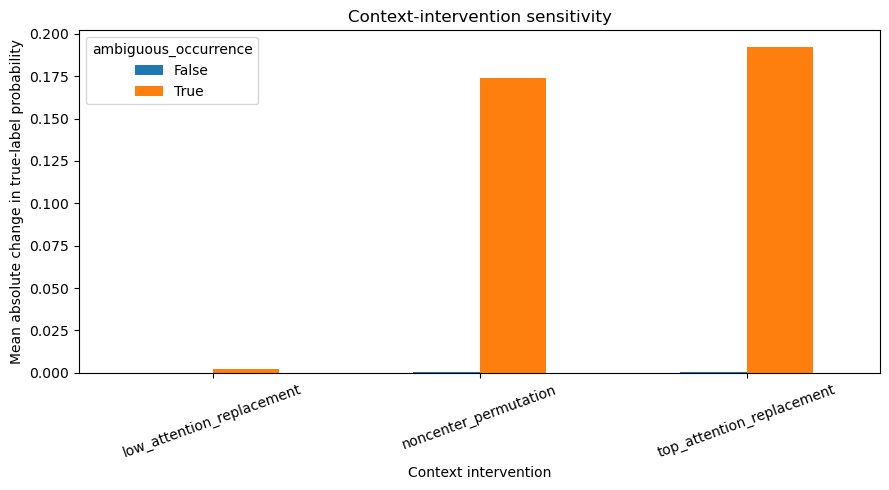

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.2\result images\hw6_2\task9_intervention_sensitivity.png


In [12]:
plot_summary = (
    intervention_frame
    .groupby(
        [
            "ambiguous_occurrence",
            "intervention",
        ]
    )[
        "absolute_true_probability_change"
    ]
    .mean()
    .unstack(0)
)

plot_summary.plot(
    kind="bar",
    figsize=(9, 5),
)

plt.xlabel("Context intervention")
plt.ylabel(
    "Mean absolute change in true-label probability"
)
plt.title(
    "Context-intervention sensitivity"
)
plt.xticks(rotation=20)
plt.tight_layout()

path = (
    RESULT_DIR
    / "task9_intervention_sensitivity.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

# My Assessment of the LLM Response

The intervention results support the LLM's main **testable** prediction, but they also show why the interpretation must remain narrow.

## 1. Did high-attention replacement matter more than the low-attention control?

Yes, very strongly for ambiguous occurrences. For ambiguous centers, replacing the highest-attended non-center symbol produced a mean absolute change in true-label probability of

$$
0.19248,
$$

whereas replacing the lowest-attended non-center symbol produced only

$$
0.00203.
$$

The corresponding argmax prediction-change rates were

$$
37.04\% \quad\text{versus}\quad 0.82\%.
$$

Thus the high-attention intervention was about two orders of magnitude larger in probability effect. This supports the claim that, **for this trained model and these ambiguous examples, high-attention context positions are associated with much greater output sensitivity than low-attention positions**.

For unambiguous centers the same ordering holds, but both effects are tiny: the mean absolute true-probability change is approximately

$$
3.98\times 10^{-4}
$$

for top-attention replacement and

$$
1.12\times 10^{-5}
$$

for low-attention replacement. Only about 1.17% of unambiguous predictions change under the top-attention replacement and none change under the low-attention replacement.

## 2. Did context permutation have the predicted effect?

Yes. For ambiguous centers, permuting all non-center positions gives a mean absolute change in true-label probability of

$$
0.17421
$$

and changes the argmax prediction on

$$
38.07\%
$$

of the sampled occurrences. This is vastly larger than the low-attention control and is comparable to the top-attention replacement. The mean signed drop in true-label probability is also positive and substantial:

$$
0.09152
$$

for permutation and

$$
0.07801
$$

for top-attention replacement.

For unambiguous occurrences, permutation again has only a very small effect. Therefore the model is genuinely sensitive to the surrounding arrangement primarily when the center symbol is ambiguous.

## 3. Were ambiguous occurrences more context-sensitive?

Yes. This is the clearest aggregate result. Under top-attention replacement, the mean absolute probability change is about

$$
\frac{0.19248}{0.0003976}\approx 484
$$

times larger for ambiguous than unambiguous occurrences. Prediction changes occur for 37.04% of ambiguous cases but only 1.17% of unambiguous cases. The permutation experiment gives the same qualitative conclusion.

This supports the assignment's intended distinction: context can help distinguish different **occurrences of a many-to-one observed symbol**.

## 4. Do the interventions prove that attention weights are causal explanations?

No. They provide much stronger evidence than visualization alone, because changing a high-attention position perturbs the output far more than changing a low-attention position. However, the intervention is still a model intervention rather than a complete causal decomposition. Replacing a token can create an unusual or out-of-distribution context, and the network also contains residual connections, feed-forward layers, embeddings, and nonlinear interactions. Therefore the correct conclusion is that high-attention positions are **predictively important under these interventions**, not that the attention weights uniquely explain the model's reasoning.

## 5. Did the two selected examples generalize?

Only at the level of the broad claim that ambiguous predictions depend on context. The selected examples are illustrative and were chosen because the same merged symbol had different underlying values and was decoded correctly in both contexts. The 1,000-position intervention sample provides the aggregate evidence. It does **not** establish that the particular offsets highlighted in the two plots represent universal linguistic rules.

## 6. Did attention help more in the ambiguous experiment?

Not consistently. At 5% and 10% anchors, attention has a modest positive advantage over the matched MLP on ambiguous occurrences (about +0.97 and +1.19 percentage points). At 20% anchors, however, attention is worse by about 1.78 percentage points on ambiguous occurrences, and at 40% it is also slightly worse on that metric. In the bijective case the unanchored attention advantage is exactly zero at every anchor level.

Therefore the data do **not** support the general statement that attention is superior to a matched MLP. The intervention results instead support the more precise statement that the attention model has learned context-sensitive behavior for ambiguous symbols even though that behavior does not consistently translate into higher held-out decoding accuracy.

## 7. Contextual disambiguation is not unrevealed-name recovery

This distinction is essential. At the 20% anchor level in the ambiguous experiment, attention obtains

$$
7.34\%
$$

unanchored accuracy, while the matched MLP obtains

$$
8.15\%.
$$

Thus attention does not solve the naming problem for genuinely unrevealed syllables. Its strongest demonstrated benefit is sensitivity to context when the observed symbol is many-to-one and the possible values are represented in the permitted pseudo-label supervision.

## Final Step 9 critique

The LLM's narrow intervention predictions are supported: high-attention replacement and context permutation are much more disruptive than the low-attention control, especially for ambiguous occurrences. What is **not** supported is any stronger story that attention has discovered linguistic rules, that attention weights are a complete causal explanation, or that contextual attention overcomes the fundamental identifiability problem for unrevealed syllable names.

# Step 9 outputs

- `task9_preintervention_evidence.txt`
- `task9_llm_critic_prompt.txt`
- `task9_llm_critic_response.txt`
- `task9_context_interventions.csv`
- `task9_context_intervention_summary.csv`
- `task9_intervention_sensitivity.png`

The LLM interpretation, explicit intervention predictions, and the evidence-based critique are now recorded in this notebook.